# Warp inference test (upscale / downscale)

Standalone notebook version of `SGO/env/ir/inference_engine/infer_numpy/test_infer_warp.py`.

Copied from:
- `env/ir/inference_engine/infer_numpy/infer_numpy_nodes.py` — `np_warp`, `infer_warp` (warp only, no other nodes)
- `env/ir/inference_engine/infer_numpy/tester_utils.py` — `MockGraph`
- `env/ir/inference_engine/infer_numpy/test_infer_warp.py` — test logic

`Blob` / `Node` / `Format` / `Dimensions` / `NodeWarp` are minimal local stand-ins.
Requires only `numpy` (plots below additionally need `matplotlib`).

In [1]:
import numpy as np


# ---------------------------------------------------------------------------
# Minimal stand-ins for env.api.models classes (attribute holders only)
# ---------------------------------------------------------------------------
class Format:
    def __init__(self, sign=False, exponent=0, mantissa=8):
        self.sign = sign
        self.exponent = exponent
        self.mantissa = mantissa


class Dimensions:
    def __init__(self, x=0, y=0, z=0, n=0):
        self.x = x
        self.y = y
        self.z = z
        self.n = n


class NodeWarp:
    def __init__(self, limit=None, reference_offset=None):
        self.limit = limit
        self.reference_offset = reference_offset


class Node:
    def __init__(self, name='', warp=None):
        self.name = name
        self.warp = warp


class Blob:
    def __init__(self, name='', format=None):
        self.name = name
        self.format = format


# ---------------------------------------------------------------------------
# Copied from env/ir/inference_engine/infer_numpy/tester_utils.py
# ---------------------------------------------------------------------------
class MockGraph:
    class MockLog:
        def debug(self, msg):
            pass

    def __init__(self, mock_blob_data, blob_dict):
        self._mock_blob_data = mock_blob_data
        self._blob_dict = blob_dict
        self._log = MockGraph.MockLog()

    def get_node_blobs_data(self, node):
        return self._mock_blob_data

    def get_blob(self, node, blob_name):
        return self._blob_dict[blob_name]

    def set_blob_data(self, blob, blob_data):
        self._mock_blob_data[f'_{blob.name}'] = blob_data

    @property
    def log(self):
        return self._log


## Warp inference

`np_warp` + `infer_warp` copied verbatim from `infer_numpy_nodes.py`.
`infer_warp` derives the per-axis fraction bits from `node.warp.limit` and the grid blob
format, dequantizes the int16 grid, applies bilinear interpolation via `np_warp`, and
returns an int32 result scaled by `2 ** (2 * frac_bits)` (product of the two interpolation weights).

In [2]:
def np_warp(src, warp_grid):
    height, width = warp_grid.shape[2:]
    src_height, src_width = src.shape[2:]
    xs, ys = np.meshgrid(np.arange(width), np.arange(height))
    xs = xs + warp_grid[0, 0, ...]
    ys = ys + warp_grid[0, 1, ...]
    xs0 = np.clip(np.floor(xs), 0, src_width - 2).astype(np.int32)
    ys0 = np.clip(np.floor(ys), 0, src_height - 2).astype(np.int32)

    w00 = np.clip(xs0 + 1 - xs, 0, 1) * np.clip(ys0 + 1 - ys, 0, 1)
    w10 = np.clip(xs0 + 1 - xs, 0, 1) * np.clip(ys - ys0, 0, 1)
    w01 = np.clip(xs - xs0, 0, 1) * np.clip(ys0 + 1 - ys, 0, 1)
    w11 = np.clip(xs - xs0, 0, 1) * np.clip(ys - ys0, 0, 1)

    out00 = src[..., ys0, xs0] * w00[np.newaxis, np.newaxis, ...]
    out01 = src[..., ys0, xs0 + 1] * w01[np.newaxis, np.newaxis, ...]
    out10 = src[..., ys0 + 1, xs0] * w10[np.newaxis, np.newaxis, ...]
    out11 = src[..., ys0 + 1, xs0 + 1] * w11[np.newaxis, np.newaxis, ...]

    out = out00 + out01 + out10 + out11

    return out


def infer_warp(graph, node):
    blobs_data = graph.get_node_blobs_data(node)
    warp_grid = blobs_data['_input'].copy()
    reference = blobs_data['_warp._reference']
    # calculate fractional bits from limit - need to take from hw policy
    # e.g. grid type int16, limit 127 need 7 bits for int part, 8 bits for fraction (this is per axes x/y)
    grid_node = graph.get_blob(node, '_input')
    mantissa = grid_node.format.mantissa
    pixel_bit_limit = np.log2([node.warp.limit.x, node.warp.limit.y])
    pixel_bit_limit = np.floor(pixel_bit_limit + 1.)
    min_frac_bit_limit = np.full((2,), (mantissa + grid_node.format.sign) // 2)
    frac_bits = np.min(np.stack((mantissa - pixel_bit_limit, min_frac_bit_limit)), axis=0).reshape(1, 2, 1, 1)
    assert np.all(frac_bits >= 0) >= 0, 'number of fraction bits in warp-grid is not supported for negative values'
    float_warp_grid = warp_grid * 2. ** - frac_bits
    float_reference = reference.astype(np.float64)
    offset = node.warp.reference_offset or Dimensions(x=0, y=0, z=0, n=0)
    offset = np.array([offset.x, offset.y], dtype=np.float64).reshape([1, -1, 1, 1])
    limit = np.array([node.warp.limit.x, node.warp.limit.y], dtype=np.float64).reshape([1, -1, 1, 1])
    float_warp_grid = np.clip(float_warp_grid, -limit, limit) + offset
    out_data = np_warp(float_reference, float_warp_grid)

    # This multiplication is due to the fact that warp implementation has bilinear interpolation
    # Which comes down to multiplication of two numbers with fl=frac_bits each. In order to
    # return to non float number we need to multiply the result in 2 ** (2 * frac_bits)
    # Same as we do when we force bias delta to be the multiplication of ker and input deltas
    # We could have use float_reference as reference * 2. ** -reference_frac_bits and then
    # we would do out_data = (out_data * 2 ** (2 * frac_bits * ref_frac_bits)).astype(np.uint16)
    out_data = (out_data * 2 ** (np.sum(frac_bits)))
    assert np.array_equal(out_data, out_data.astype(np.int32))
    out_data = out_data.astype(np.int32)
    out_blob = graph.get_blob(node, '_output')
    graph.set_blob_data(out_blob, out_data)
    graph.log.debug('inferred warp node: %s' % node.name)


## Test helpers

Image generation, scale-grid creation, quantized HW grid and the float
`grid_sample` reference (mirrors `torch.nn.functional.grid_sample`).

In [3]:
def generate_bg(width, height) -> np.ndarray:
    grad = np.round(np.linspace(0, 1, height) * (255 - 135) + 135)
    val = np.vstack([grad, np.ones_like(grad) * 206, np.ones_like(grad) * 235]).astype(np.uint8)
    sky = np.tile(val.T[:, np.newaxis, :], [1, width, 1])
    return sky


def generate_green_ball(width, height, img) -> np.ndarray:
    center = (width // 2, height // 2)  # Center of the image
    radius = width // 4
    xs, ys = np.meshgrid(np.arange(width) - center[0], np.arange(height) - center[1])
    dist = np.hypot(xs, ys)
    mask = dist < radius
    grad = 1 - dist / radius
    ball = np.zeros_like(img)
    ball[..., 1] = np.clip(grad * 255, 0, 255)
    img = np.where(mask[..., np.newaxis], ball, img)
    return img


def generate_image(height, width) -> np.ndarray:

    # Create image
    image = generate_bg(width, height)

    # Add green ball with gradient and texture
    image = generate_green_ball(width, height, image)
    return image


def grid_sample(tensor: np.ndarray, grid: np.ndarray) -> np.ndarray:
    """Given an input and a flow-field grid, computes the output using input
    values and pixel locations from grid.

    Args:
        tensor: (N, C, H_in, W_in) tensor
        grid: (N, H_out, W_out, 2) tensor in the range of [-1, 1]

    Returns:
        (N, C, H_out, W_out) tensor

    See `torch.nn.functional.grid_sample`.
    """
    b, c, h, w = tensor.shape
    b_, h_out, w_out, w_ = grid.shape
    assert b == b_ and w_ == 2
    out = []
    for (t, g) in zip(tensor, grid):
        x_ = 0.5 * (w - 1) * (g[..., 0].reshape(-1) + 1)
        y_ = 0.5 * (h - 1) * (g[..., 1].reshape(-1) + 1)
        ix = np.floor(x_).astype(np.int32).clip(0, w - 2)
        iy = np.floor(y_).astype(np.int32).clip(0, h - 2)
        dx = x_ - ix
        dy = y_ - iy
        out.append((1 - dx) * (1 - dy) * t[..., iy, ix]
                   + dx * (1 - dy) * t[..., iy, ix + 1]
                   + (1 - dx) * dy * t[..., iy + 1, ix]
                   + dx * dy * t[..., iy + 1, ix + 1])
    return np.concatenate(out, axis=0).reshape(b, c, h_out, w_out)


def create_scale_grid(reference_height, reference_width, grid_height, grid_width):
    grid = np.dstack(np.meshgrid(np.linspace(0, reference_width - 1, grid_width),
                                 np.linspace(0, reference_height - 1, grid_height)))
    grid = grid[np.newaxis, ...]
    return grid


def calculate_scale_hw_grid(
    reference_width: int,
    reference_height: int,
    grid_width: int,
    grid_height: int,
    grid_bit_width: int,
) -> np.ndarray:
    grid = create_scale_grid(
        reference_height, reference_width, grid_height, grid_width)[0]
    loc_grid = np.dstack(np.meshgrid(np.arange(grid_width), np.arange(grid_height)))
    grid = grid - loc_grid
    max_motion = np.ceil(np.abs(grid.reshape((-1, 2))).max(axis=0))
    frac_bits = grid_bit_width - np.floor(np.log2(max_motion)) - 2
    grid = np.round(grid * 2.0 ** frac_bits).astype(np.int16)
    grid = grid.transpose((2, 0, 1))[np.newaxis, ...]
    return grid


## Run one warp test

Compares three results:
- **expected** — float grid through `grid_sample`
- **q_expected** — quantized (16-bit HW) grid through `grid_sample`
- **result** — quantized grid through the HW model `infer_warp`

Assert: `q_expected` and HW `result` match with `atol=1`.

In [4]:
def run_warp_test(x: np.ndarray, grid: np.ndarray, grid_bits: int, name: str):
    new_h, new_w = grid.shape[-3:-1]
    orig_h, orig_w = x.shape[-2:]
    grid_norm_scale = 2 / np.array([orig_w - 1, orig_h - 1]).reshape((1, 1, 1, -1))
    loc_grid = np.dstack(np.meshgrid(np.arange(new_w), np.arange(new_h)))[np.newaxis, ...]
    delta_grid = grid - loc_grid
    max_motion = np.ceil(np.abs(delta_grid.reshape((-1, 2))).max(axis=0))
    frac_bits = grid_bits - np.floor(np.log2(max_motion)) - 2

    hw_grid = calculate_scale_hw_grid(
        orig_w,
        orig_h,
        new_w,
        new_h,
        grid_bits
    )
    q_grid = hw_grid.transpose((0, 2, 3, 1)) / 2. ** frac_bits + loc_grid

    grid = grid_norm_scale * grid - 1
    q_grid = grid_norm_scale * q_grid - 1

    expected = grid_sample(x, grid)
    q_expected = grid_sample(x, q_grid)
    warp_props = NodeWarp()
    warp_props.limit = Dimensions(x=max_motion[0], y=max_motion[1])
    node = Node(name='warper', warp=warp_props)
    blobs_data = {
        '_input': hw_grid,
        '_warp._reference': x.copy(),
        '_output': np.empty_like(expected, dtype=np.int32)
    }
    blobs = {
        '_input': Blob(name='grid', format=Format(sign=True, exponent=0, mantissa=15)),
        '_output': Blob(name='output', format=Format(sign=True, exponent=0, mantissa=31))
    }
    graph = MockGraph(blobs_data, blobs)
    infer_warp(graph, node)
    result = blobs_data['_output'].reshape(expected.shape)
    result = result / 2. ** (frac_bits.sum())

    print(f'[{name}] mse expected vs q_expected : {((expected - q_expected) ** 2).mean():.3f}')
    print(f'[{name}] mse q_expected vs hw result: {((q_expected - result) ** 2).mean():.3f}')

    assert np.allclose(q_expected, result, atol=1), \
        f'[{name}] hw warp result mismatch (atol=1)'
    print(f'[{name}] PASS')
    return x, expected, q_expected, result


## Downscale: 320x240 -> 106x80

In [ ]:
reference_height, reference_width, grid_height, grid_width = 240, 320, 80, 106
grid_bits = 16
x = generate_image(reference_height, reference_width).transpose([2, 0, 1])[np.newaxis, ...]
grid = create_scale_grid(reference_height, reference_width, grid_height, grid_width)

x_dn, exp_dn, qexp_dn, res_dn = run_warp_test(x, grid, grid_bits, 'downscale')


[downscale] mse expected vs q_expected : 0.002
[downscale] mse q_expected vs hw result: 0.000
[downscale] PASS


## Upscale: 80x45 -> 2400x1350

In [ ]:
reference_height, reference_width, grid_height, grid_width = 45, 80, 1350, 2400
grid_bits = 16
x = generate_image(reference_height, reference_width).transpose([2, 0, 1])[np.newaxis, ...]
grid = create_scale_grid(reference_height, reference_width, grid_height, grid_width)

x_up, exp_up, qexp_up, res_up = run_warp_test(x, grid, grid_bits, 'upscale')


[upscale] mse expected vs q_expected : 1.359
[upscale] mse q_expected vs hw result: 0.000
[upscale] PASS


## Visualization

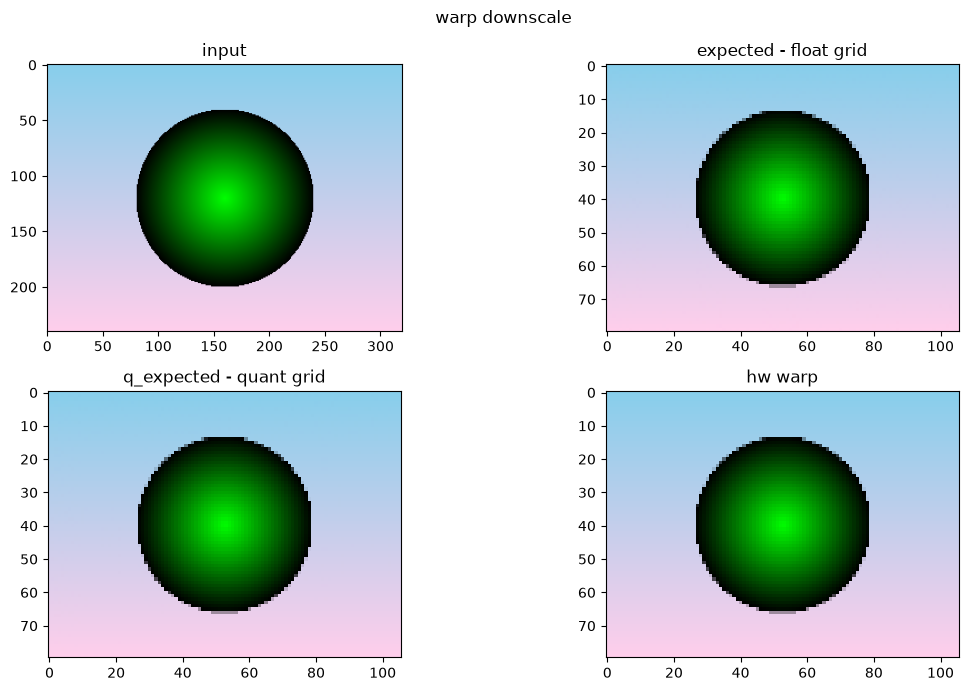

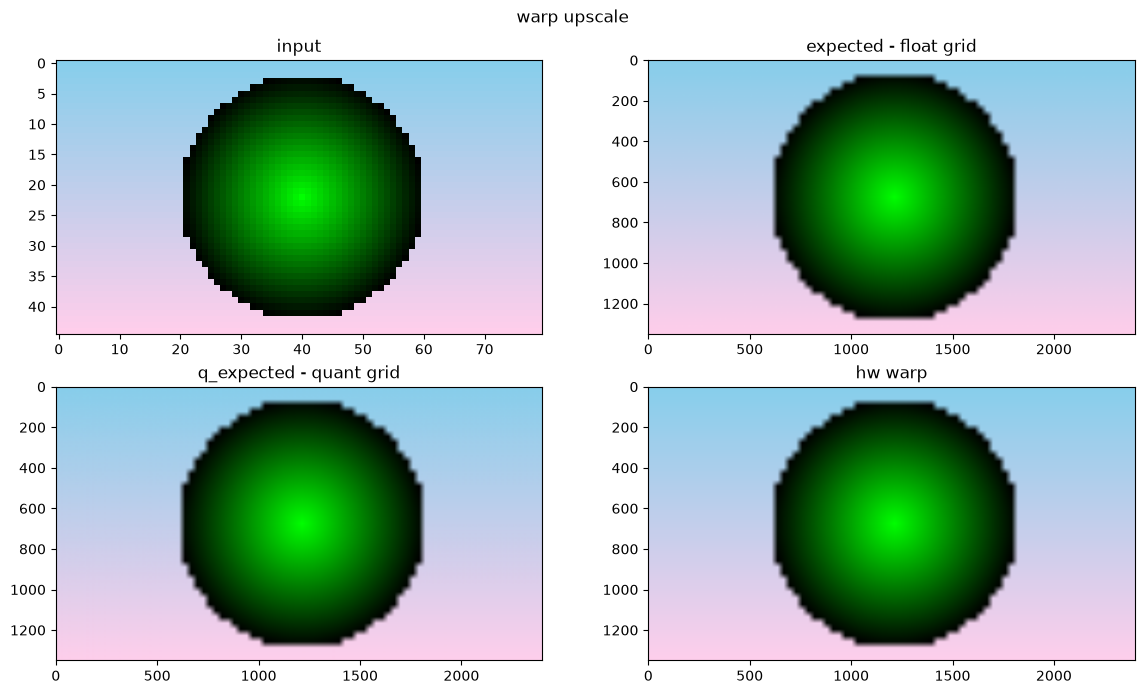

In [7]:
import matplotlib.pyplot as plt


def show_all(x, expected, q_expected, result, name):
    to_img = lambda t: t.squeeze().transpose((1, 2, 0)).astype(np.uint8)
    fig, axs = plt.subplots(2, 2, figsize=(12, 7))
    axs[0, 0].imshow(to_img(x));            axs[0, 0].set_title('input')
    axs[0, 1].imshow(to_img(expected));     axs[0, 1].set_title('expected - float grid')
    axs[1, 0].imshow(to_img(q_expected));   axs[1, 0].set_title('q_expected - quant grid')
    axs[1, 1].imshow(to_img(result));       axs[1, 1].set_title('hw warp')
    fig.suptitle(f'warp {name}')
    plt.tight_layout()
    plt.show()


show_all(x_dn, exp_dn, qexp_dn, res_dn, 'downscale')
show_all(x_up, exp_up, qexp_up, res_up, 'upscale')
